# Portfolio 3: Load-Class Forecasting with Traditional ML and LSTM (Zone 1, Tetouan City)

This notebook continues Portfolio 1 (EDA) and Portfolio 2 (K-means load classes, feature engineering, DT/SVM).
The task here is **classification**: predict the Zone 1 load class (`Base Load`, `Normal Load`, `Peak Load`) **1 hour ahead**.

- **Part A** – Random Forest and MLP classifiers on tabular features.
- **Part B** – LSTM classifier on sequences of past observations.
- **Part C** – Master results table and reflection.

Kernel: conda env `aistuff` (Python 3.11, scikit-learn, TensorFlow/Keras).

In [1]:
import os, time, pickle, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, f1_score, recall_score, log_loss,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
for d in ['figures', 'models', 'results']:
    os.makedirs(d, exist_ok=True)

CLASS_NAMES = ['Base Load', 'Normal Load', 'Peak Load']
H = 6  # forecast horizon: 6 steps x 10 min = 1 hour ahead

## 1. Load and Analyse the Dataset (Step A.1)

The raw file gives the timestamp and the continuous Zone 1 load (kW). The class labels are the 3 K-means classes created in Portfolio 2
(`converted_power_consumption.csv`, same row order as the raw file). The target `zone_1_load_class` is categorical, so this is a
**classification problem**. Column cleaning and the `hour`/`month` extraction follow Portfolio 1/2.

In [2]:
raw = pd.read_csv('../data/Tetuan City power consumption.csv')
labels = pd.read_csv('../data/converted_power_consumption.csv')

# Same snake_case cleaning as Portfolio 1/2
raw.columns = (raw.columns.str.strip().str.replace(r'\s+', ' ', regex=True)
               .str.lower().str.replace(' ', '_'))
raw['datetime'] = pd.to_datetime(raw['datetime'])
raw['hour'] = raw['datetime'].dt.hour
raw['month'] = raw['datetime'].dt.month

df = raw.drop(columns=['zone_2_power_consumption', 'zone_3_power_consumption'])
df['zone_1_load_class'] = labels['zone_1_load_class'].values  # Portfolio 2 K-means labels

print('Shape:', df.shape)
print('Rows in chronological order:', df['datetime'].is_monotonic_increasing)
display(df.head())
display(df['zone_1_load_class'].value_counts().sort_index().rename(index=dict(enumerate(CLASS_NAMES))))

Shape: (52416, 10)
Rows in chronological order: True


,datetime,temperature,humidity,wind_speed,general_diffuse_flows,diffuse_flows,zone_1_power_consumption,hour,month,zone_1_load_class
0,2017-01-01 00:00:00,6.559,73.8,0.083,0.051,0.119,34055.69620,0,1,1
1,2017-01-01 00:10:00,6.414,74.5,0.083,0.070,0.085,29814.68354,0,1,1
2,2017-01-01 00:20:00,6.313,74.5,0.080,0.062,0.100,29128.10127,0,1,1
3,2017-01-01 00:30:00,6.121,75.0,0.083,0.091,0.096,28228.86076,0,1,0
4,2017-01-01 00:40:00,5.921,75.7,0.081,0.048,0.085,27335.69620,0,1,0


zone_1_load_class
Base Load      18099
Normal Load    21888
Peak Load      12429
Name: count, dtype: int64

## 2. Problem Framing: Chronological Split and 1-Hour Horizon

Readings 10 minutes apart are almost identical, so a shuffled split (used in Portfolio 2) lets the model see near-copies of test rows during
training. Because an LSTM needs ordered sequences, **all models in this notebook use the same chronological 80/20 split**: the first 80% of
the year is used for training and the last 20% (mid-October to December) for testing.

The task is to predict the class **1 hour ahead** (`class[t+6]`) using information available up to time `t`. Predicting the very next
10-minute step is trivial because the class changes on only ~3.5% of steps. The naive baselines below set the bar any model has to beat.

Train period: 2017-01-01 00:00:00 -> 2017-10-19 04:30:00
Test period : 2017-10-19 04:40:00 -> 2017-12-30 23:50:00


,Overall,Train (first 80%),Test (last 20%)
Base Load,34.5,31.7,45.7
Normal Load,41.8,41.9,41.0
Peak Load,23.7,26.3,13.3


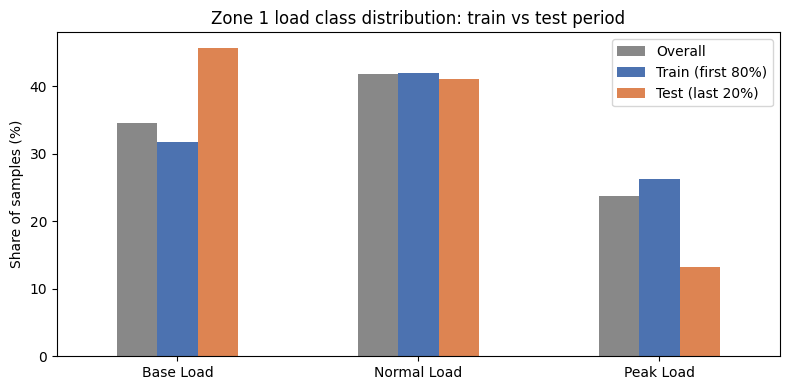

,Test accuracy
Persistence (10 min ago),0.9693
Persistence-1h (class at t),0.8283
Seasonal-24h (same time yesterday),0.8946


Share of 10-min steps where the class changes: 0.0346


In [3]:
N = len(df)
SPLIT = int(N * 0.8)  # first time index whose class belongs to the test period
y_all = df['zone_1_load_class'].values
print(f'Train period: {df.datetime[0]} -> {df.datetime[SPLIT - 1]}')
print(f'Test period : {df.datetime[SPLIT]} -> {df.datetime[N - 1]}')

dist = pd.DataFrame({
    'Overall': np.bincount(y_all) / N * 100,
    'Train (first 80%)': np.bincount(y_all[:SPLIT]) / SPLIT * 100,
    'Test (last 20%)': np.bincount(y_all[SPLIT:]) / (N - SPLIT) * 100,
}, index=CLASS_NAMES)
display(dist.round(1))

ax = dist.plot(kind='bar', figsize=(8, 4), rot=0, color=['#888888', '#4C72B0', '#DD8452'])
ax.set_ylabel('Share of samples (%)')
ax.set_title('Zone 1 load class distribution: train vs test period')
plt.tight_layout()
plt.savefig('figures/p3_class_shift.png', dpi=150)
plt.show()

# Naive baselines on the test targets class[t+H]
test_t = np.arange(SPLIT - H, N - H)  # anchor times whose target falls in the test period
y_test_ref = y_all[test_t + H]
baselines = {
    'Persistence (10 min ago)': y_all[test_t + H - 1],
    'Persistence-1h (class at t)': y_all[test_t],
    'Seasonal-24h (same time yesterday)': y_all[test_t + H - 144],
}
display(pd.DataFrame({'Test accuracy': {k: accuracy_score(y_test_ref, v) for k, v in baselines.items()}}).round(4))
print('Share of 10-min steps where the class changes:', round((y_all[1:] != y_all[:-1]).mean(), 4))

## 3. Part A: Traditional ML Models

### 3.1 Feature sets (Step A.2)
Two feature sets are compared so that we can separate the effect of *load history* from the effect of the *model*:

- **Set A – weather + time (16 features)**: the 7 original predictors plus the 9 engineered features from Portfolio 2 Task 3
  (recomputed here in raw units, because P3 requires scalers fitted on the training period only).
- **Set B – Set A + load history (22 features)**: adds the Zone 1 load at `t`, `t-10 min`, `t-1 h`, `t-24 h`, the 1-hour rolling mean and the
  1-hour change. These are all known at time `t`, so there is no leakage. The LSTM in Part B sees the same kind of history.

The first 144 rows (24 h) are dropped because `load_t-144` needs one day of history, and the last 6 rows have no target 1 h ahead.

In [4]:
feat = df.copy()

# Engineered features from Portfolio 2 (Task 3)
feat['diffuse_fraction'] = feat['diffuse_flows'] / (feat['general_diffuse_flows'] + 1e-5)
feat['temp_humidity_index'] = feat['temperature'] * feat['humidity']
feat['solar_thermal_load'] = feat['general_diffuse_flows'] * feat['temperature']
feat['convective_cooling_ratio'] = feat['temperature'] / (feat['wind_speed'] + 1.0)
feat['hour_sin'] = np.sin(2 * np.pi * feat['hour'] / 24)
feat['hour_cos'] = np.cos(2 * np.pi * feat['hour'] / 24)
feat['month_sin'] = np.sin(2 * np.pi * (feat['month'] - 1) / 12)
feat['month_cos'] = np.cos(2 * np.pi * (feat['month'] - 1) / 12)
feat['is_evening_peak'] = feat['hour'].between(17, 22).astype(int)

# Load history known at time t
load = feat['zone_1_power_consumption']
feat['load_t'] = load
feat['load_t-1'] = load.shift(1)
feat['load_t-6'] = load.shift(6)
feat['load_t-144'] = load.shift(144)
feat['load_roll_mean_6'] = load.rolling(6).mean()
feat['load_diff_6'] = load - load.shift(6)

feat['target'] = feat['zone_1_load_class'].shift(-H)  # class 1 hour ahead

SET_A = ['temperature', 'humidity', 'wind_speed', 'general_diffuse_flows', 'diffuse_flows', 'hour', 'month',
         'diffuse_fraction', 'temp_humidity_index', 'solar_thermal_load', 'convective_cooling_ratio',
         'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'is_evening_peak']
SET_B = SET_A + ['load_t', 'load_t-1', 'load_t-6', 'load_t-144', 'load_roll_mean_6', 'load_diff_6']
FEATURE_SETS = {'Set A (weather+time)': SET_A, 'Set B (+load history)': SET_B}

data = feat.iloc[144:N - H]
print('Modelling rows:', data.shape[0], '| Missing values:', data[SET_B + ['target']].isna().sum().sum())

Modelling rows: 52266 | Missing values: 0


### 3.2 Scaling and chronological 80/20 split (Step A.2)
A sample anchored at `t` goes to the test set when its target time `t+6` is in the last 20% of the year. `StandardScaler` is fitted on the
training rows only and then applied to the test rows.

In [5]:
train = data[data.index + H < SPLIT]
test = data[data.index + H >= SPLIT]
y_train = train['target'].astype(int).values
y_test = test['target'].astype(int).values

X = {}
for name, cols in FEATURE_SETS.items():
    scaler = StandardScaler().fit(train[cols])
    X[name] = (scaler.transform(train[cols]), scaler.transform(test[cols]))
    print(f'{name}: X_train {X[name][0].shape}, X_test {X[name][1].shape}')
print('y_train', y_train.shape, '| y_test', y_test.shape)
print('Test targets identical to baseline targets:', np.array_equal(y_test, y_test_ref))

Set A (weather+time): X_train (41782, 16), X_test (10484, 16)


Set B (+load history): X_train (41782, 22), X_test (10484, 22)
y_train (41782,) | y_test (10484,)
Test targets identical to baseline targets: True


### 3.3 Train the two models (Step A.3)
- **Random Forest**: 300 trees, `min_samples_leaf=5` to stop the trees memorising single noisy readings (the DT overfitting issue in Portfolio 2).
- **MLP Classifier**: two hidden layers (64, 32), ReLU, Adam, L2 `alpha=1e-4`, early stopping on a 10% validation split.

Each model is trained on both feature sets (4 fits).

In [6]:
def make_models():
    return {
        'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=SEED),
        'MLP': MLPClassifier(hidden_layer_sizes=(64, 32), activation='relu', solver='adam', alpha=1e-4,
                             early_stopping=True, validation_fraction=0.1, max_iter=300, random_state=SEED),
    }

def evaluate(name, model_type, y_true, y_pred, proba=None):
    return {'Model type': model_type, 'Model': name,
            'Accuracy': accuracy_score(y_true, y_pred),
            'Weighted F1': f1_score(y_true, y_pred, average='weighted'),
            'Macro F1': f1_score(y_true, y_pred, average='macro'),
            'Peak recall': recall_score(y_true, y_pred, labels=[2], average=None)[0],
            'Test log loss': log_loss(y_true, proba, labels=[0, 1, 2]) if proba is not None else np.nan}

results = [evaluate(k, 'Naive baseline', y_test_ref, v)
           for k, v in baselines.items() if k != 'Persistence (10 min ago)']
partA_preds = {}
for set_name, (Xtr, Xte) in X.items():
    for model_name, model in make_models().items():
        t0 = time.time()
        model.fit(Xtr, y_train)
        name = f'{model_name} - {set_name}'
        partA_preds[name] = model.predict(Xte)
        results.append(evaluate(name, 'Traditional ML', y_test, partA_preds[name], model.predict_proba(Xte)))
        print(f'{name}: fitted in {time.time() - t0:.1f}s, test accuracy {results[-1]["Accuracy"]:.4f}')

Random Forest - Set A (weather+time): fitted in 1.3s, test accuracy 0.7930


MLP - Set A (weather+time): fitted in 3.0s, test accuracy 0.7912


Random Forest - Set B (+load history): fitted in 1.4s, test accuracy 0.9040


MLP - Set B (+load history): fitted in 3.2s, test accuracy 0.8899


### 3.4 Evaluation and 5-fold cross-validation (Step A.4)
Cross-validation uses `TimeSeriesSplit(n_splits=5)` on the training period: each fold trains on the past and validates on the following
block, which respects time order. The scaler is inside a pipeline, so it is refitted on each training fold.

In [7]:
tscv = TimeSeriesSplit(n_splits=5)
cv_scores = {}
for set_name, cols in FEATURE_SETS.items():
    for model_name, model in make_models().items():
        scores = cross_val_score(make_pipeline(StandardScaler(), model), train[cols], y_train,
                                 cv=tscv, scoring='accuracy', n_jobs=-1 if model_name == 'MLP' else None)
        cv_scores[f'{model_name} - {set_name}'] = scores

for r in results:
    s = cv_scores.get(r['Model'])
    r['CV accuracy (mean)'] = s.mean() if s is not None else np.nan
    r['CV accuracy (std)'] = s.std() if s is not None else np.nan

partA_table = pd.DataFrame(results).set_index('Model')
display(partA_table.drop(columns='Model type').round(4))
display(pd.DataFrame(cv_scores, index=[f'Fold {i + 1}' for i in range(5)]).T.round(4))

,Accuracy,Weighted F1,Macro F1,Peak recall,Test log loss,CV accuracy (mean),CV accuracy (std)
Model,,,,,,,
Persistence-1h (class at t),0.8283,0.8283,0.7994,0.7115,NaN,NaN,NaN
Seasonal-24h (same time yesterday),0.8946,0.8947,0.8879,0.8777,NaN,NaN,NaN
Random Forest - Set A (weather+time),0.7930,0.7999,0.7780,0.8835,0.6424,0.7581,0.1198
MLP - Set A (weather+time),0.7912,0.7942,0.7908,0.9374,0.8167,0.6920,0.0941
Random Forest - Set B (+load history),0.9040,0.9062,0.8837,0.8899,0.2253,0.9029,0.0483
MLP - Set B (+load history),0.8899,0.8930,0.8637,0.9719,0.3799,0.8621,0.0466


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5
Random Forest - Set A (weather+time),0.9108,0.8967,0.6618,0.6829,0.6384
MLP - Set A (weather+time),0.7175,0.8528,0.6898,0.6200,0.5799
Random Forest - Set B (+load history),0.9463,0.9499,0.8180,0.8865,0.9135
MLP - Set B (+load history),0.8570,0.9453,0.8439,0.8024,0.8618


In [8]:
best_A = partA_table[partA_table['Model type'] == 'Traditional ML']['Accuracy'].idxmax()
print('Best traditional model:', best_A)
print(classification_report(y_test, partA_preds[best_A], target_names=CLASS_NAMES, digits=4))

Best traditional model: Random Forest - Set B (+load history)
              precision    recall  f1-score   support

   Base Load     0.9954    0.9121    0.9520      4791
 Normal Load     0.8709    0.8996    0.8850      4303
   Peak Load     0.7502    0.8899    0.8141      1390

    accuracy                         0.9040     10484
   macro avg     0.8722    0.9006    0.8837     10484
weighted avg     0.9118    0.9040    0.9062     10484



### 3.5 Visualise results (Step A.5)

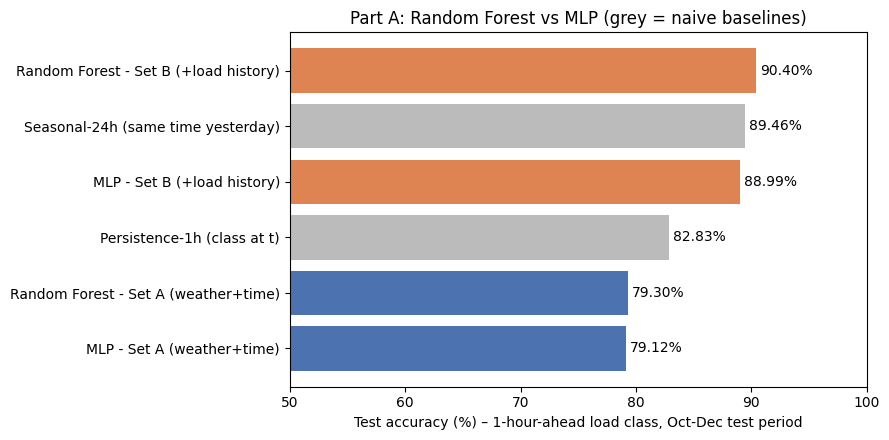

In [9]:
plot_df = partA_table[['Accuracy', 'Weighted F1']].sort_values('Accuracy')
colors = ['#BBBBBB' if 'Persistence' in i or 'Seasonal' in i else ('#4C72B0' if 'Set A' in i else '#DD8452')
          for i in plot_df.index]
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(plot_df.index, plot_df['Accuracy'] * 100, color=colors)
ax.bar_label(bars, fmt='%.2f%%', padding=3)
ax.set_xlim(50, 100)
ax.set_xlabel('Test accuracy (%) – 1-hour-ahead load class, Oct-Dec test period')
ax.set_title('Part A: Random Forest vs MLP (grey = naive baselines)')
plt.tight_layout()
plt.savefig('figures/p3_partA_bar.png', dpi=150)
plt.show()

### 3.6 Part A observations
- **Best traditional model: Random Forest on Set B** (90.40% accuracy, 0.906 weighted F1, TimeSeriesSplit CV 90.29% ± 4.83%).
- **Load history matters most.** Adding past load lifts both models by ~10-11 points (RF 79.30% -> 90.40%, MLP 79.12% -> 88.99%).
  Weather and time alone cannot beat even the 1-hour persistence baseline (82.83%).
- **Only a small margin over the naive seasonal baseline.** "Same class as 24 h ago" already scores 89.46%, so the RF adds ~1 point. Most
  of the predictability comes from the daily cycle.
- **Why RF beats MLP:** the class boundaries are thresholds on load and hour, which trees model directly with axis-aligned splits. Bagging
  300 trees with `min_samples_leaf=5` reduces the variance that hurt the single Decision Tree in Portfolio 2. The MLP needs more tuning and
  ends with a higher test log loss (0.38 vs 0.23).
- **Time-based CV is less stable than P2's shuffled CV.** Set A folds range from 64% to 91%, because later folds (autumn) differ from the
  winter/spring folds the model was trained on. This is the seasonal drift a random split would hide.

## 4. Part B: LSTM Classifier

### 4.1 Prepare sequential data (Step B.1)
Each sample is a window of the last `L` readings (`t-L+1 … t`) with 10 features per timestep: the 5 weather signals, the cyclical hour and
month encodings, and the Zone 1 load itself. The label is the load class 1 hour later (`class[t+6]`), so the samples, split and test
targets are the same as in Part A. `MinMaxScaler` (0–1) is fitted on the training period only.

**Sequence lengths**
- **L = 36 (6 hours)**: covers one full ramp, plateau or evening surge, which is the local shape the next hour depends on.
- **L = 144 (24 hours)**: one full daily cycle. The autocorrelation below peaks again at lag 144, and the 24 h seasonal baseline already
  reaches 89.5%, so a full day of history should help.

In [10]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.random.set_seed(SEED)
keras.utils.set_random_seed(SEED)

print('Zone 1 load autocorrelation:',
      {f'lag {k} ({k * 10 // 60} h)': round(float(load.autocorr(k)), 3) for k in [6, 36, 72, 144]})

SEQ_FEATURES = ['temperature', 'humidity', 'wind_speed', 'general_diffuse_flows', 'diffuse_flows',
                'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'zone_1_power_consumption']
mm = MinMaxScaler().fit(feat[SEQ_FEATURES].iloc[:SPLIT - H])  # rows only seen as training inputs
Z = mm.transform(feat[SEQ_FEATURES]).astype('float32')

def make_sequences(L):
    t = np.arange(L - 1, N - H)  # anchor = last timestep of each window
    windows = np.lib.stride_tricks.sliding_window_view(Z, L, axis=0).transpose(0, 2, 1)  # (N-L+1, L, F)
    Xs, ys = windows[t - (L - 1)], y_all[t + H]
    is_test = t + H >= SPLIT
    return Xs[~is_test], ys[~is_test], Xs[is_test], ys[is_test]

SEQ = {}
for L in [36, 144]:
    SEQ[L] = make_sequences(L)
    Xtr, ytr, Xte, yte = SEQ[L]
    print(f'L={L}: X_train {Xtr.shape}, y_train {ytr.shape}, X_test {Xte.shape}, y_test {yte.shape}, '
          f'same test targets as Part A: {np.array_equal(yte, y_test)}')

Zone 1 load autocorrelation: {'lag 6 (1 h)': 0.913, 'lag 36 (6 h)': 0.002, 'lag 72 (12 h)': -0.378, 'lag 144 (24 h)': 0.962}
L=36: X_train (41891, 36, 10), y_train (41891,), X_test (10484, 36, 10), y_test (10484,), same test targets as Part A: True
L=144: X_train (41783, 144, 10), y_train (41783,), X_test (10484, 144, 10), y_test (10484,), same test targets as Part A: True


### 4.2 LSTM architecture (Step B.2)
Architecture as specified: LSTM(64, return_sequences=True) -> Dropout(0.2) -> LSTM(32) -> Dropout(0.2) -> Dense(16, ReLU) ->
Dense(3, Softmax). Compiled with Adam, sparse categorical cross-entropy (integer labels 0/1/2) and accuracy. The parameter count does not
depend on `L`, because LSTM weights are shared across timesteps.

In [11]:
def build_lstm(L, n_features=len(SEQ_FEATURES), n_classes=3):
    model = keras.Sequential([
        keras.Input(shape=(L, n_features)),
        layers.LSTM(64, return_sequences=True),
        layers.Dropout(0.2),
        layers.LSTM(32, return_sequences=False),
        layers.Dropout(0.2),
        layers.Dense(16, activation='relu'),
        layers.Dense(n_classes, activation='softmax'),
    ], name=f'lstm_L{L}')
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

build_lstm(36).summary()

Model: "lstm_L36"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 36, 64)         │        19,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 36, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32,195 (125.76 KB)

 Trainable params: 32,195 (125.76 KB)

 Non-trainable params: 0 (0.00 B)

### 4.3 Train the model (Step B.3)

**Batch-size check.** L = 36 is trained for 10 epochs with batch sizes 16, 32 and 64. Batch size is chosen by the lowest validation loss.
`validation_split=0.2` uses the **last** 20% of the training windows (Keras takes it before shuffling), so validation is also later in
time than training.

In [12]:
Xtr36, ytr36, Xte36, yte36 = SEQ[36]
sweep = []
for bs in [16, 32, 64]:
    keras.utils.set_random_seed(SEED)
    model = build_lstm(36)
    t0 = time.time()
    h = model.fit(Xtr36, ytr36, batch_size=bs, epochs=10, validation_split=0.2, verbose=0).history
    best = int(np.argmin(h['val_loss']))
    sweep.append({'Batch size': bs, 'Best epoch': best + 1, 'Val loss': h['val_loss'][best],
                  'Val accuracy': h['val_accuracy'][best], 'Train accuracy': h['accuracy'][best],
                  'Time (s)': round(time.time() - t0)})
sweep_df = pd.DataFrame(sweep).set_index('Batch size')
display(sweep_df.round(4))
BEST_BS = int(sweep_df['Val loss'].idxmin())
print('Selected batch size:', BEST_BS)

,Best epoch,Val loss,Val accuracy,Train accuracy,Time (s)
Batch size,,,,,
16,9,0.3370,0.8475,0.9416,158
32,10,0.3925,0.7908,0.9391,87
64,10,0.4536,0.7778,0.9351,54


Selected batch size: 16


**Final training.** Two LSTM configurations are trained for up to 50 epochs with
`EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)` and `ReduceLROnPlateau(factor=0.5, patience=5)`:

| Model | Sequence length | Batch size |
|---|---|---|
| **LSTM-1** | 36 (6 h) | best from the sweep |
| **LSTM-2** | 144 (24 h) | 64 (longer windows cost more per step; 64 keeps training time reasonable) |

In [13]:
CONFIGS = {'LSTM-1 (L=36)': (36, BEST_BS), 'LSTM-2 (L=144)': (144, 64)}
lstm_models, histories = {}, {}
for name, (L, bs) in CONFIGS.items():
    Xtr, ytr, _, _ = SEQ[L]
    keras.utils.set_random_seed(SEED)
    model = build_lstm(L)
    callbacks = [keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
                 keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, verbose=1)]
    t0 = time.time()
    h = model.fit(Xtr, ytr, batch_size=bs, epochs=50, validation_split=0.2, callbacks=callbacks, verbose=0)
    lstm_models[name], histories[name] = model, h.history
    best = int(np.argmin(h.history['val_loss']))
    print(f'{name}: {len(h.history["loss"])} epochs run, best epoch {best + 1}, '
          f'val_loss {h.history["val_loss"][best]:.4f}, val_acc {h.history["val_accuracy"][best]:.4f}, '
          f'{time.time() - t0:.0f}s')


Epoch 16: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.



Epoch 21: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.


LSTM-1 (L=36): 21 epochs run, best epoch 11, val_loss 0.3163, val_acc 0.8592, 339s



Epoch 27: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.



Epoch 32: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.


LSTM-2 (L=144): 32 epochs run, best epoch 22, val_loss 0.3602, val_acc 0.8618, 626s


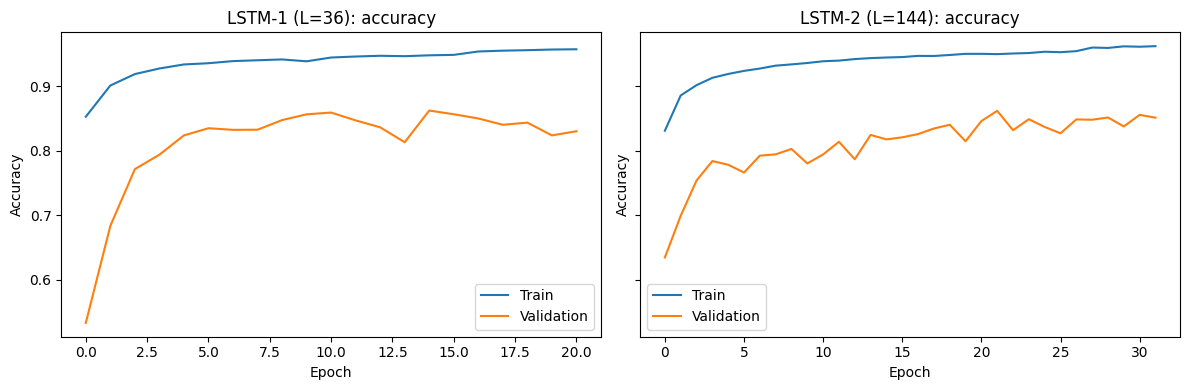

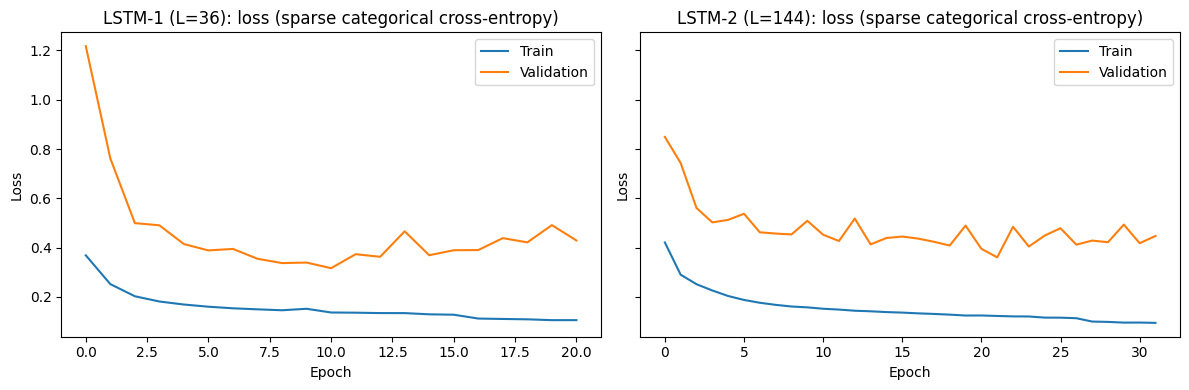

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (name, h) in zip(axes, histories.items()):
    ax.plot(h['accuracy'], label='Train')
    ax.plot(h['val_accuracy'], label='Validation')
    ax.set_title(f'{name}: accuracy')
    ax.set_xlabel('Epoch'); ax.set_ylabel('Accuracy'); ax.legend()
plt.tight_layout(); plt.savefig('figures/p3_acc_curves.png', dpi=150); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (name, h) in zip(axes, histories.items()):
    ax.plot(h['loss'], label='Train')
    ax.plot(h['val_loss'], label='Validation')
    ax.set_title(f'{name}: loss (sparse categorical cross-entropy)')
    ax.set_xlabel('Epoch'); ax.set_ylabel('Loss'); ax.legend()
plt.tight_layout(); plt.savefig('figures/p3_loss_curves.png', dpi=150); plt.show()

### 4.4 Evaluate the LSTM models (Step B.4)

===== LSTM-1 (L=36): test loss 0.2837, test accuracy 0.9093
              precision    recall  f1-score   support

   Base Load     0.9741    0.9324    0.9528      4791
 Normal Load     0.9128    0.8613    0.8863      4303
   Peak Load     0.7399    0.9784    0.8426      1390

    accuracy                         0.9093     10484
   macro avg     0.8756    0.9240    0.8939     10484
weighted avg     0.9179    0.9093    0.9109     10484



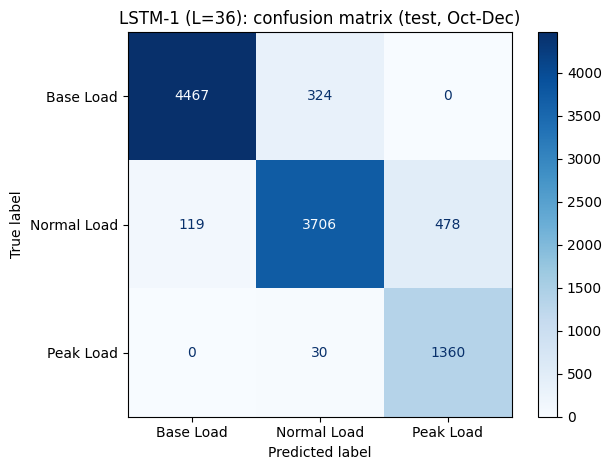

===== LSTM-2 (L=144): test loss 0.3408, test accuracy 0.8935
              precision    recall  f1-score   support

   Base Load     0.9930    0.8844    0.9355      4791
 Normal Load     0.8617    0.8819    0.8717      4303
   Peak Load     0.7363    0.9604    0.8336      1390

    accuracy                         0.8935     10484
   macro avg     0.8637    0.9089    0.8803     10484
weighted avg     0.9051    0.8935    0.8958     10484



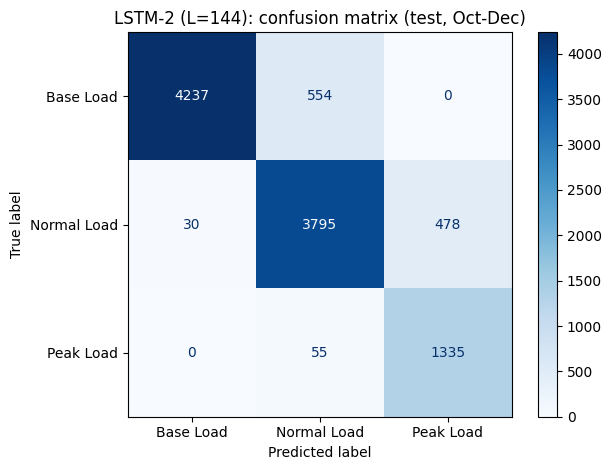

,Accuracy,Weighted F1,Macro F1,Peak recall,Test log loss
Model,,,,,
LSTM-1 (L=36),0.9093,0.9109,0.8939,0.9784,0.2837
LSTM-2 (L=144),0.8935,0.8958,0.8803,0.9604,0.3408
Seasonal-24h (same time yesterday),0.8946,0.8947,0.8879,0.8777,NaN
Random Forest - Set B (+load history),0.9040,0.9062,0.8837,0.8899,0.2253


In [15]:
lstm_results = []
for name, model in lstm_models.items():
    L = CONFIGS[name][0]
    _, _, Xte, yte = SEQ[L]
    test_loss, test_acc = model.evaluate(Xte, yte, verbose=0)
    proba = model.predict(Xte, verbose=0)
    pred = proba.argmax(axis=1)
    print(f'===== {name}: test loss {test_loss:.4f}, test accuracy {test_acc:.4f}')
    print(classification_report(yte, pred, target_names=CLASS_NAMES, digits=4))
    lstm_results.append(evaluate(name, 'Deep Learning', yte, pred, proba))

    ConfusionMatrixDisplay(confusion_matrix(yte, pred), display_labels=CLASS_NAMES).plot(cmap='Blues', values_format='d')
    plt.title(f'{name}: confusion matrix (test, Oct-Dec)')
    plt.tight_layout(); plt.savefig(f'figures/p3_cm_L{L}.png', dpi=150); plt.show()

compare = pd.DataFrame(lstm_results + [r for r in results if r['Model'] in [best_A, 'Seasonal-24h (same time yesterday)']])
display(compare.set_index('Model').drop(columns=['Model type', 'CV accuracy (mean)', 'CV accuracy (std)'], errors='ignore').round(4))

### 4.5 Save the models (Step B.5)
Each model is saved in Keras `.h5` format and its training history as a pickle. Reloading the `.h5` file and re-scoring confirms the
saved file reproduces the test accuracy.

In [16]:
for name, model in lstm_models.items():
    L = CONFIGS[name][0]
    model.save(f'models/lstm_L{L}.h5')
    with open(f'models/history_L{L}.pkl', 'wb') as f:
        pickle.dump(histories[name], f)

    reloaded = keras.models.load_model(f'models/lstm_L{L}.h5')
    with open(f'models/history_L{L}.pkl', 'rb') as f:
        n_epochs = len(pickle.load(f)['loss'])
    _, _, Xte, yte = SEQ[L]
    print(f'models/lstm_L{L}.h5 reloaded: test accuracy {reloaded.evaluate(Xte, yte, verbose=0)[1]:.4f} | '
          f'history_L{L}.pkl: {n_epochs} epochs')

models/lstm_L36.h5 reloaded: test accuracy 0.9093 | history_L36.pkl: 21 epochs


models/lstm_L144.h5 reloaded: test accuracy 0.8935 | history_L144.pkl: 32 epochs


### 4.6 LSTM vs best traditional model (Step B.4)
- **LSTM-1 (L=36) outperformed every other model**: 90.93% accuracy, 0.911 weighted F1, 0.894 macro F1 and 97.8% Peak recall, against
  90.40% / 0.906 / 0.884 / 89.0% for the best traditional model (Random Forest, Set B).
- **The margin is small.** LSTM-1 is +0.53 points over the RF and +1.47 points over the Seasonal-24h baseline. This is a single run with one
  seed, so the gap over the RF is suggestive rather than conclusive.
- **Why the LSTM helps:** the RF only sees six hand-picked load lags. The LSTM sees the full 6-hour trajectory of load and weather and can
  learn the *shape* of the ramp (rising, flat or falling) that decides whether the next hour crosses a class boundary. This shows mainly in
  Peak recall (97.8% vs 89.0%).
- **Where it is weaker:** the RF has a lower test log loss (0.225 vs 0.284), so its probabilities are better calibrated. The LSTM is also
  over-eager on Peak: 478 Normal-load hours are predicted as Peak (Peak precision 0.74). It learned from a summer-heavy training period
  (26% Peak) and was tested on Oct–Dec (13% Peak).
- **All errors are between neighbouring classes.** No Base hour is ever predicted as Peak, or the other way round. The mistakes happen at
  class boundaries, which is expected when a continuous load is cut into bins.
- **LSTM-2 (L=144) did worse** (89.35%) than both LSTM-1 and the RF, and slightly below the Seasonal-24h baseline. The longer window did
  not pay off (see Section 5.3).

## 5. Part C: Final Summary

### 5.1 Master results table (Step C.1)
All models are scored on the same 10,484 test targets (load class 1 hour ahead, 19 Oct – 30 Dec). Primary metric: accuracy.
Secondary metric: test log loss (the LSTM's test loss; not defined for the naive baselines, which give no probabilities).

,Model type,Model,Accuracy,Test log loss,Weighted F1,Macro F1,Peak recall,CV accuracy (mean)
0,Naive baseline,Persistence-1h (class at t),0.8283,NaN,0.8283,0.7994,0.7115,NaN
1,Naive baseline,Seasonal-24h (same time yesterday),0.8946,NaN,0.8947,0.8879,0.8777,NaN
2,Traditional ML,Random Forest - Set A (weather+time),0.7930,0.6424,0.7999,0.7780,0.8835,0.7581
3,Traditional ML,MLP - Set A (weather+time),0.7912,0.8167,0.7942,0.7908,0.9374,0.6920
4,Traditional ML,Random Forest - Set B (+load history),0.9040,0.2253,0.9062,0.8837,0.8899,0.9029
5,Traditional ML,MLP - Set B (+load history),0.8899,0.3799,0.8930,0.8637,0.9719,0.8621
6,Deep Learning,LSTM-1 (L=36),0.9093,0.2837,0.9109,0.8939,0.9784,NaN
7,Deep Learning,LSTM-2 (L=144),0.8935,0.3408,0.8958,0.8803,0.9604,NaN


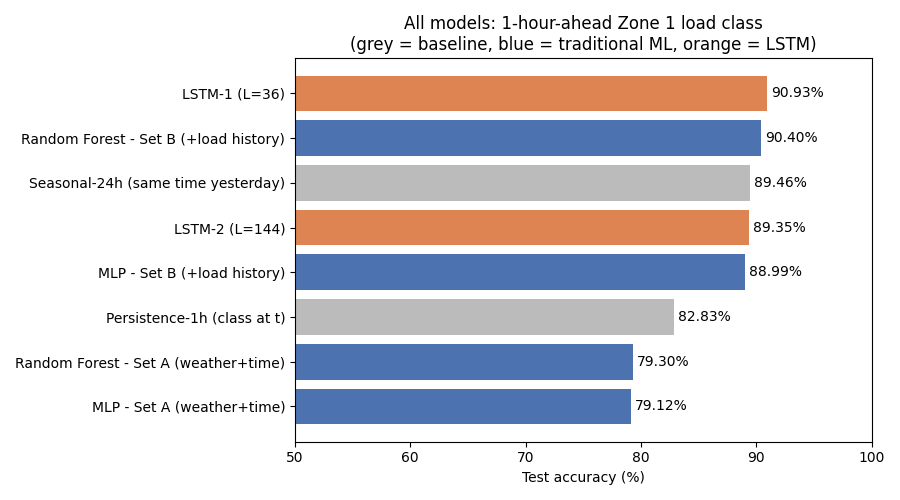

In [17]:
master = pd.DataFrame(results + lstm_results)
master = master[['Model type', 'Model', 'Accuracy', 'Test log loss', 'Weighted F1', 'Macro F1', 'Peak recall', 'CV accuracy (mean)']]
master.to_csv('results/p3_master_table.csv', index=False)
display(master.round(4))

plot_df = master.set_index('Model').sort_values('Accuracy')
palette = {'Naive baseline': '#BBBBBB', 'Traditional ML': '#4C72B0', 'Deep Learning': '#DD8452'}
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(plot_df.index, plot_df['Accuracy'] * 100, color=plot_df['Model type'].map(palette))
ax.bar_label(bars, fmt='%.2f%%', padding=3)
ax.set_xlim(50, 100)
ax.set_xlabel('Test accuracy (%)')
ax.set_title('All models: 1-hour-ahead Zone 1 load class\n(grey = baseline, blue = traditional ML, orange = LSTM)')
plt.tight_layout(); plt.savefig('figures/p3_master_bar.png', dpi=150); plt.show()

### 5.2 Best model (Step C.2)
**Which model performed best?** LSTM-1 (sequence length 36, batch size 16) has the highest accuracy (90.93%), weighted F1 (0.911),
macro F1 (0.894) and Peak recall (97.8%) on the Oct–Dec test period.

**Why?** It is the only model that uses the whole recent trajectory of load and weather, not a fixed set of lags. A 6-hour window is long
enough to capture the morning ramp and evening surge, and short enough for a two-layer LSTM to learn from with ~42k training windows.
Batch size 16 gave the most weight updates per epoch and the lowest validation loss in the sweep.

**Would I deploy it in production?** Not as the only model, for these reasons:
- It beats a free "same time yesterday" rule by only ~1.5 points, and a much cheaper, more interpretable Random Forest by ~0.5 points.
- 26% of its Peak alarms are false (Normal predicted as Peak). Each false alarm can trigger unnecessary reserve dispatch.
- It was trained and tested on a single year. Seasonal drift is visible: validation loss is noisy and the class mix changes from summer to
  winter, so it would need a retraining schedule and drift monitoring.
- The RF gives better-calibrated probabilities, which matters if operators act on a confidence threshold.

A realistic deployment would run the LSTM in shadow mode next to the RF and the seasonal baseline. It would be promoted only if it keeps
its edge over several months of walk-forward evaluation.

### 5.3 Reflection questions (Step C.3)
**How did the architecture choices affect performance?**
- **Sequence length:** L=36 (6 h) beat L=144 (24 h) by 1.6 points. Error signals have to pass back through 144 LSTM steps, which makes the
  long window harder to train. The daily cycle the long window was meant to capture is already given explicitly by the `hour_sin/cos`
  features. L=144 also costs ~3x more compute per epoch.
- **Batch size:** in the 10-epoch sweep, batch 16 reached validation loss 0.337 vs 0.393 (32) and 0.454 (64). Smaller batches give more
  updates per epoch and noisier gradients, which acted as mild regularisation. The cost is ~3x the training time of batch 64.
- **Dropout, early stopping and LR reduction:** training loss kept falling to ~0.10 while validation loss stayed around 0.32–0.45. The gap
  reflects both overfitting and the validation period (Aug–Oct) differing from the training period. Early stopping kept the best
  epoch (11 for LSTM-1, 22 for LSTM-2), and `ReduceLROnPlateau` halved the learning rate twice in each run. Dropout 0.2 was not enough to
  close the gap.
- **Size:** the two stacked LSTM layers (64 -> 32) have only 32,195 parameters. That was enough capacity; extra capacity would mainly add
  overfitting.

**Did the deep learning model outperform traditional ML? Why or why not?**
Yes, but only slightly, and only with the 6-hour window. LSTM-1 beat the best Random Forest by 0.53 points in accuracy and 8.8 points in Peak
recall, because it learns the load trajectory instead of a few fixed lags. The RF still had better-calibrated probabilities, trains in
~2 s instead of ~6 min, and is interpretable. The bigger lesson is that **information matters more than the model**: adding load history
lifted the traditional models by 10–11 points, while switching from RF to LSTM added half a point.

**If I had more time, what would I do to improve performance?**
1. **Fairer evaluation:** walk-forward (rolling-origin) evaluation and several random seeds for the LSTM, so the 0.5-point gap gets a
   confidence interval.
2. **Missing calendar features:** day of week, weekends, public holidays and Ramadan (late May to late June 2017), all of which change
   residential load in Morocco.
3. **Fix the Peak false alarms:** class weights or probability-threshold tuning on a validation period, plus probability calibration.
4. **Remove label leakage:** refit the K-means class thresholds on the training period only (Portfolio 2 fitted them on the full year).
5. **Other architectures and inputs:** tune L between 12 and 72, try GRU / 1D-CNN or an attention layer, and add weather forecasts for
   the next hour as future inputs.
6. **More data:** several years of telemetry so that every season appears in both training and testing.